# Evaluation en Programmation - Initiation IA

L’objectif est de créer un système d’aide à la décision basé sur l’apprentissage automatique pour aider les dresseurs de Pokemons à choisir le bon Pokemon afin de leur assurer une victoire lors de chaque combat.
\
A partir des fichiers _pokedex.csv_ et _combats.csv_ (à télécharger de votre page moodle), nous allons étudier et préparer les données au profit de ce système d'aide à la décision.

# Partie 1 (13 points - 1 point/question)

1. Créez un dossier _myEvalData_ au même niveau que votre fichier _Python_.
\
Placez-y les fichiers _pokedex.csv_ et _combats.csv_
et chargez le fichier _pokedex.csv_ dans la DataFrame nommée _nosPokemons_.

**<span style="color:red">
ATTENTION \
</span>**
La fonction _read_csv_ peut nécessiter un encodage spécifique pour l'ouverture de votre fichier. Dans ce cas, il faut spécifier la valeur de l'argument _encoding_ sinon l’exception _UnicodeDecodeError_ sera déclenchée.\
Vous pouvez essayer d'attribuer la valeur "cp1252" à l'argument encoding de la fonction read_csv comme suit :
\
_**read_csv("...csv", encoding="cp1252")**_ 
\
Ceci fait référence à la page de code Windows-1252, également connue sous le nom de "Windows Latin 1." C'est un encodage couramment utilisé pour les fichiers texte dans les systèmes Windows.

**<span style="color:red">
RÉPONSE\
</span>**

In [3]:
import pandas as pnd
nosPokemons = pnd.read_csv("myEvalData/pokedex.csv", encoding = "cp1252")

2. Affichez juste les dimensions de la dataFrame nosPokemons (lignes, colonnes)

**<span style="color:red">
RÉPONSE\
</span>**

In [4]:
nosPokemons.shape

(800, 12)

3. Listez les colonnes de la dataFrame _nosPokemons_

**<span style="color:red">
RÉPONSE\
</span>**

In [9]:
list(nosPokemons.columns.values)

['NUMERO',
 'NOM',
 'TYPE_1',
 'TYPE_2',
 'POINTS_DE_VIE',
 'POINTS_ATTAQUE',
 'POINTS_DEFFENCE',
 'POINTS_ATTAQUE_SPECIALE',
 'POINT_DEFENSE_SPECIALE',
 'POINTS_VITESSE',
 'NOMBRE_GENERATIONS',
 'LEGENDAIRE']

4. Affichez les informations générales de la DataFrame _nosPokemons_

**<span style="color:red">
RÉPONSE\
</span>**

In [11]:
nosPokemons.info(verbose=True,show_counts=True)
nosPokemons.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   NUMERO                   800 non-null    int64 
 1   NOM                      799 non-null    object
 2   TYPE_1                   800 non-null    object
 3   TYPE_2                   413 non-null    object
 4   POINTS_DE_VIE            800 non-null    int64 
 5   POINTS_ATTAQUE           800 non-null    int64 
 6   POINTS_DEFFENCE          800 non-null    int64 
 7   POINTS_ATTAQUE_SPECIALE  800 non-null    int64 
 8   POINT_DEFENSE_SPECIALE   800 non-null    int64 
 9   POINTS_VITESSE           800 non-null    int64 
 10  NOMBRE_GENERATIONS       800 non-null    int64 
 11  LEGENDAIRE               800 non-null    object
dtypes: int64(8), object(4)
memory usage: 75.1+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 12 columns

5. Affichez les 10 premières lignes de la DataFrame _nosPokemons_

**<span style="color:red">
RÉPONSE\
</span>**

In [12]:
nosPokemons.head(10)
nosPokemons.head()

,NUMERO,NOM,TYPE_1,TYPE_2,POINTS_DE_VIE,POINTS_ATTAQUE,POINTS_DEFFENCE,POINTS_ATTAQUE_SPECIALE,POINT_DEFENSE_SPECIALE,POINTS_VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE
0,1,Bulbizarre,Herbe,Poison,45,49,49,65,65,45,1,FAUX
1,2,Herbizarre,Herbe,Poison,60,62,63,80,80,60,1,FAUX
2,3,Florizarre,Herbe,Poison,80,82,83,100,100,80,1,FAUX
3,4,Mega Florizarre,Herbe,Poison,80,100,123,122,120,80,1,FAUX
4,5,Salamèche,Feu,NaN,39,52,43,60,50,65,1,FAUX


6. Affichez uniquement les valeurs de la feature LEGENDAIRE.

**<span style="color:red">
RÉPONSE\
</span>**

In [16]:
nosPokemons[['LEGENDAIRE']]

,LEGENDAIRE
0,FAUX
1,FAUX
2,FAUX
3,FAUX
4,FAUX
...,...
795,VRAI
796,VRAI
797,VRAI
798,VRAI


7. Remarquez que les valeurs sont actuellement des chaines de caractères : VRAI ou FAUX (Par exemple : les pokémons n°795, 796 et 797 sont légendaires). Transformez les valeurs en données numériques pour qu’elle soit exploitable par l'IA: 1 si VRAI et 0 si FAUX et réaffichez la colonne pour vérifier la transformation.

**<span style="color:red">
RÉPONSE\
</span>**

In [17]:
nosPokemons['LEGENDAIRE']=(nosPokemons['LEGENDAIRE'] == 'VRAI').astype(int)
nosPokemons[['LEGENDAIRE']]

,LEGENDAIRE
0,0
1,0
2,0
3,0
4,0
...,...
795,1
796,1
797,1
798,1


8. Remarquez aussi qu'il manque quelques données. Certaines informations manquantes sont faciles à trouver comme par exemple le nom du Pokémon manquant. En consultant une source sure, nous trouvons le nom du Pokémon, il s’agit de ‘Colossinge’. Ajoutez-le au bon endroit dans le fichier.

Trouvez et affichez la ligne de la DataFrame nosPokemons concernée par le nom manquant.

**<span style="color:red">
RÉPONSE\
</span>**

In [18]:
print(nosPokemons[nosPokemons['NOM'].isnull()])
nosPokemons[nosPokemons['NOM'].isnull()]

    NUMERO  NOM  TYPE_1 TYPE_2  POINTS_DE_VIE  POINTS_ATTAQUE  \
62      63  NaN  Combat    NaN             65             105   

    POINTS_DEFFENCE  POINTS_ATTAQUE_SPECIALE  POINT_DEFENSE_SPECIALE  \
62               60                       60                      70   

    POINTS_VITESSE  NOMBRE_GENERATIONS LEGENDAIRE  
62              95                   1       FAUX  


0      False
1      False
2      False
3      False
4      False
       ...  
795    False
796    False
797    False
798    False
799    False
Name: NOM, Length: 800, dtype: bool

9. Maintenant, faites la modification.

**<span style="color:red">
RÉPONSE\
</span>**

In [21]:
print(nosPokemons.at[62,'NOM'])
nosPokemons.at[62,'NOM']='Colossinge'
print(nosPokemons.at[62,'NOM'])

Colossinge
Colossinge


10. Affichez la ligne concernée par la modification pour vérifier que la modification a bien eu lieu.

**<span style="color:red">
RÉPONSE\
</span>**

In [26]:
nosPokemons.iloc[62]

NUMERO                             63
NOM                        Colossinge
TYPE_1                         Combat
TYPE_2                            NaN
POINTS_DE_VIE                      65
POINTS_ATTAQUE                    105
POINTS_DEFFENCE                    60
POINTS_ATTAQUE_SPECIALE            60
POINT_DEFENSE_SPECIALE             70
POINTS_VITESSE                     95
NOMBRE_GENERATIONS                  1
LEGENDAIRE                          0
Name: 62, dtype: object

11. Affichez les pokémons légendaires ayant POINTS_DE_VIE >=50

**<span style="color:red">
RÉPONSE\
</span>**

In [28]:
nosPokemons[(nosPokemons['LEGENDAIRE']==1) & (nosPokemons['POINTS_DE_VIE']>=50)]

,NUMERO,NOM,TYPE_1,TYPE_2,POINTS_DE_VIE,POINTS_ATTAQUE,POINTS_DEFFENCE,POINTS_ATTAQUE_SPECIALE,POINT_DEFENSE_SPECIALE,POINTS_VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE
156,157,Artikodin,Glace,Vol,90,85,100,95,125,85,1,1
157,158,Électhor,Electrique,Vol,90,90,85,125,90,100,1,1
158,159,Sulfura,Feu,Vol,90,100,90,125,85,90,1,1
162,163,Mewtwo,Psy,NaN,106,110,90,154,90,130,1,1
163,164,Mega Mewtwo X,Psy,Combat,106,190,100,154,100,130,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,Diancie,Roche,Fée,50,100,150,100,150,50,6,1
796,797,Mega Diancie,Roche,Fée,50,160,110,160,110,110,6,1
797,798,Hoopa confiné,Psy,Spectre,80,110,60,150,130,70,6,1
798,799,Hoopa non lié,Psy,Obscur,80,160,60,170,130,80,6,1


12. Affichez les pokémons ayant POINTS_ATTAQUE >=50 ou POINTS_ATTAQUE_SPECIALE>=60

**<span style="color:red">
RÉPONSE\
</span>**

In [29]:
nosPokemons[(nosPokemons['POINTS_ATTAQUE']>=50) | (nosPokemons['POINTS_ATTAQUE_SPECIALE']>=60)]

,NUMERO,NOM,TYPE_1,TYPE_2,POINTS_DE_VIE,POINTS_ATTAQUE,POINTS_DEFFENCE,POINTS_ATTAQUE_SPECIALE,POINT_DEFENSE_SPECIALE,POINTS_VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE
0,1,Bulbizarre,Herbe,Poison,45,49,49,65,65,45,1,0
1,2,Herbizarre,Herbe,Poison,60,62,63,80,80,60,1,0
2,3,Florizarre,Herbe,Poison,80,82,83,100,100,80,1,0
3,4,Mega Florizarre,Herbe,Poison,80,100,123,122,120,80,1,0
4,5,Salamèche,Feu,NaN,39,52,43,60,50,65,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,Diancie,Roche,Fée,50,100,150,100,150,50,6,1
796,797,Mega Diancie,Roche,Fée,50,160,110,160,110,110,6,1
797,798,Hoopa confiné,Psy,Spectre,80,110,60,150,130,70,6,1
798,799,Hoopa non lié,Psy,Obscur,80,160,60,170,130,80,6,1


13. Affichez les pokémons ayant POINT_DEFENSE_SPECIALE entre 55 et 59

**<span style="color:red">
RÉPONSE\
</span>**

In [30]:
nosPokemons[nosPokemons['POINT_DEFENSE_SPECIALE'].between(55,59)]

,NUMERO,NOM,TYPE_1,TYPE_2,POINTS_DE_VIE,POINTS_ATTAQUE,POINTS_DEFFENCE,POINTS_ATTAQUE_SPECIALE,POINT_DEFENSE_SPECIALE,POINTS_VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE
33,34,Sablaireau,Sol,NaN,75,100,110,45,55,65,1,0
35,36,Nidorina,Poison,NaN,70,62,67,55,55,56,1,0
38,39,Nidorino,Poison,NaN,61,72,57,55,55,65,1,0
51,52,Paras,Insecte,Herbe,35,70,55,45,55,25,1,0
53,54,Mimitoss,Insecte,Poison,60,55,50,40,55,45,1,0
68,69,Abra,Psy,NaN,25,20,15,105,55,90,1,0
88,89,Magnéti,Electrique,Acier,25,35,70,95,55,45,1,0
100,101,Spectrum,Spectre,Poison,45,50,45,115,55,95,1,0
108,109,Voltorbe,Electrique,NaN,40,30,50,55,55,100,1,0
129,130,Stari,Eau,NaN,30,45,55,70,55,85,1,0


# Partie 2 (7 points - 0,5 point/question)

1. Chargez maintenant le fichier _combats.csv_ dans la DataFrame nommée _combats_.
\
Chaque ligne de ce fichier représente un combat entre 2 pokémons, un pokémon en 1ère position et l'autre en 2ème position, enfin, la dernière colonne nous indique le numéro du pokémmon vainqueur.

**<span style="color:red">
RÉPONSE\
</span>**

In [38]:
combats = pnd.read_csv("myEvalData/combats.csv")

2. Affichez les informations générales de cette dataFrame et les 10 premières lignes.

**<span style="color:red">
RÉPONSE\
</span>**

In [39]:
combats.info(verbose=True,show_counts=True)
combats.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   First_pokemon   50000 non-null  int64
 1   Second_pokemon  50000 non-null  int64
 2   Winner          50000 non-null  int64
dtypes: int64(3)
memory usage: 1.1 MB


,First_pokemon,Second_pokemon,Winner
0,266,298,298
1,702,701,701
2,191,668,668
3,237,683,683
4,151,231,151
5,657,752,657
6,192,134,134
7,73,545,545
8,220,763,763
9,302,31,31


3. L'objectif de cette question est de créer une _Series_ qui, pour chaque pokémon, précise le nombre de fois où ce dernier a combattu en 1ère position.

Créez une DataFrame appelée _nbFoisPremierePosition_ qui compte le nombre de fois où un pokémon était en 1ère position.

**<span style="color:red">
RÉPONSE\
</span>**

In [40]:
nbFoisPremierePosition = combats.groupby('First_pokemon').count()
print(nbFoisPremierePosition)
type(nbFoisPremierePosition)

               Second_pokemon  Winner
First_pokemon                        
1                          70      70
2                          55      55
3                          68      68
4                          62      62
5                          50      50
...                       ...     ...
796                        49      49
797                        64      64
798                        60      60
799                        75      75
800                        61      61

[784 rows x 2 columns]


pandas.core.frame.DataFrame

4. Transformez cette DataFrame en Series comportant uniquement la colonne 'Winner'. Changez le nom de l'index en 'NUMERO' et le nom de la Series en 'NombreDeCombats'

**<span style="color:red">
RÉPONSE\
</span>**

In [41]:
nbFoisPremierePosition = nbFoisPremierePosition['Winner']
print(nbFoisPremierePosition.index.name)
nbFoisPremierePosition.index.name='NUMERO'
print(nbFoisPremierePosition.index.name)
nbFoisPremierePosition = nbFoisPremierePosition.rename('NombreDeCombats',inplace=True)
nbFoisPremierePosition

First_pokemon
NUMERO


NUMERO
1      70
2      55
3      68
4      62
5      50
       ..
796    49
797    64
798    60
799    75
800    61
Name: NombreDeCombats, Length: 784, dtype: int64

5. De la même manière que précédemment :
* Créez une DataFrame appelée _nbFoisSecondePosition_ qui, pour chaque pokémon, précise le nombre de fois où ce dernier a combattu en seconde position. Transformez cette DataFrame en Series comportant uniquement la colonne 'Winner'. Changez le nom de l'index en 'NUMERO' et le nom de la Series en 'NombreDeCombats'

**<span style="color:red">
RÉPONSE\
</span>**

In [42]:
nbFoisSecondePosition = combats.groupby('Second_pokemon').count()
print(nbFoisSecondePosition)
type(nbFoisSecondePosition)
nbFoisSecondePosition = nbFoisSecondePosition['Winner']
print(nbFoisSecondePosition.index.name)
nbFoisSecondePosition.index.name='NUMERO'
print(nbFoisSecondePosition.index.name)
nbFoisSecondePosition = nbFoisSecondePosition.rename('NombreDeCombats',inplace=True)
nbFoisSecondePosition

                First_pokemon  Winner
Second_pokemon                       
1                          63      63
2                          66      66
3                          64      64
4                          63      63
5                          62      62
...                       ...     ...
796                        56      56
797                        67      67
798                        59      59
799                        69      69
800                        60      60

[784 rows x 2 columns]
Second_pokemon
NUMERO


NUMERO
1      63
2      66
3      64
4      63
5      62
       ..
796    56
797    67
798    59
799    69
800    60
Name: NombreDeCombats, Length: 784, dtype: int64

6. Le nombre total de combats pour un pokémon est le nombre de combats en 1ère position + le nombre de combats en seconde position. Créez la Series _nombreTotalDeCombats_ (donnez lui le nom de 'NBR_COMBATS') qui est le résultat de l'addition des dataFrames _nbFoisPremierePosition_ et _nbFoisSecondePosition_

**<span style="color:red">
RÉPONSE\
</span>**

In [46]:
df_nbFoisPremierePosition = pnd.DataFrame(nbFoisPremierePosition)
df_nbFoisSecondePosition = pnd.DataFrame(nbFoisSecondePosition)
df_nombreTotalDeCombats = df_nbFoisPremierePosition + df_nbFoisSecondePosition
df_nombreTotalDeCombats
nombreTotalDeCombats = df_nombreTotalDeCombats['NombreDeCombats']
nombreTotalDeCombats = nombreTotalDeCombats.rename('NBR_COMBATS',inplace=True)
type(nombreTotalDeCombats)
print(nombreTotalDeCombats)

NUMERO
1      133
2      121
3      132
4      125
5      112
      ... 
796    105
797    131
798    119
799    144
800    121
Name: NBR_COMBATS, Length: 784, dtype: int64


7. Créez maintenant une Series appelée _nombreDeVictoires_ qui contient le nombre de combats gagnés par Pokémon. Changez le nom de l'index en 'NUMERO' et le nom de la Series en 'NBR_VICTOIRES'

**<span style="color:red">
RÉPONSE\
</span>**

In [72]:
df_nombreDeVictoires = combats.groupby('Winner').count()
df_nombreDeVictoires
nombreDeVictoires = df_nombreDeVictoires['First_pokemon']
print(nombreDeVictoires.index.name)
nombreDeVictoires.index.name='NUMERO'
print(nombreDeVictoires.index.name)
nombreDeVictoires = nombreDeVictoires.rename('NBR_VICTOIRES',inplace=True)
nombreDeVictoires

Winner
NUMERO


NUMERO
1       37
2       46
3       89
4       70
5       55
      ... 
796     39
797    116
798     60
799     89
800     75
Name: NBR_VICTOIRES, Length: 783, dtype: int64

8. L'objectif maintenant est de rajouter à la DataFrame _nosPokemons_ les colonnes 'NBR_COMBATS' et 'NBR_VICTOIRES'

Attention, la concaténation ne marche pas car il y a des pokémons qui n'ont jamais gagné ou qui n'ont jmais été en 1ère position ou qui n'ont jamais été en 2ème position. le seul moyen est de passer par l'aggrégarion avec la fonction _merge_ (jointure).
La ligne de code qui permet de le faire pour 'NBR_COMBATS' est la suivante :

In [77]:
nouveauPokedex = nosPokemons.merge(nombreTotalDeCombats, left_on ='NUMERO', right_index = True, how='left')
nouveauPokedex

,NUMERO,NOM,TYPE_1,TYPE_2,POINTS_DE_VIE,POINTS_ATTAQUE,POINTS_DEFFENCE,POINTS_ATTAQUE_SPECIALE,POINT_DEFENSE_SPECIALE,POINTS_VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE,NBR_COMBATS
0,1,Bulbizarre,Herbe,Poison,45,49,49,65,65,45,1,0,133.0
1,2,Herbizarre,Herbe,Poison,60,62,63,80,80,60,1,0,121.0
2,3,Florizarre,Herbe,Poison,80,82,83,100,100,80,1,0,132.0
3,4,Mega Florizarre,Herbe,Poison,80,100,123,122,120,80,1,0,125.0
4,5,Salamèche,Feu,NaN,39,52,43,60,50,65,1,0,112.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,Diancie,Roche,Fée,50,100,150,100,150,50,6,1,105.0
796,797,Mega Diancie,Roche,Fée,50,160,110,160,110,110,6,1,131.0
797,798,Hoopa confiné,Psy,Spectre,80,110,60,150,130,70,6,1,119.0
798,799,Hoopa non lié,Psy,Obscur,80,160,60,170,130,80,6,1,144.0


On fait une jointure sur la colonne 'NUMERO' de notre dataFrame _nosPokemons_ et sur l'index de la DataFrame _nombreTotalDeCombats_

* Ajoutez maintenant de la même manière la colonnes 'NBR_VICTOIRES'

**<span style="color:red">
RÉPONSE\
</span>**

In [78]:
nouveauPokedex = nouveauPokedex.merge(nombreDeVictoires, left_on ='NUMERO', right_index = True, how='left')
nouveauPokedex

,NUMERO,NOM,TYPE_1,TYPE_2,POINTS_DE_VIE,POINTS_ATTAQUE,POINTS_DEFFENCE,POINTS_ATTAQUE_SPECIALE,POINT_DEFENSE_SPECIALE,POINTS_VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE,NBR_COMBATS,NBR_VICTOIRES
0,1,Bulbizarre,Herbe,Poison,45,49,49,65,65,45,1,0,133.0,37.0
1,2,Herbizarre,Herbe,Poison,60,62,63,80,80,60,1,0,121.0,46.0
2,3,Florizarre,Herbe,Poison,80,82,83,100,100,80,1,0,132.0,89.0
3,4,Mega Florizarre,Herbe,Poison,80,100,123,122,120,80,1,0,125.0,70.0
4,5,Salamèche,Feu,NaN,39,52,43,60,50,65,1,0,112.0,55.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,Diancie,Roche,Fée,50,100,150,100,150,50,6,1,105.0,39.0
796,797,Mega Diancie,Roche,Fée,50,160,110,160,110,110,6,1,131.0,116.0
797,798,Hoopa confiné,Psy,Spectre,80,110,60,150,130,70,6,1,119.0,60.0
798,799,Hoopa non lié,Psy,Obscur,80,160,60,170,130,80,6,1,144.0,89.0


9. Ajoutez à notre DataFrame nosPokemons la colonne 'TAUX_DE_VICTOIRES' = NBR_VICTOIRES/NBR_COMBATS

**<span style="color:red">
RÉPONSE\
</span>**

In [81]:
nouveauPokedex['TAUX_DE_VICTOIRES']= nouveauPokedex['NBR_VICTOIRES']/ nouveauPokedex['NBR_COMBATS']
nouveauPokedex

,NUMERO,NOM,TYPE_1,TYPE_2,POINTS_DE_VIE,POINTS_ATTAQUE,POINTS_DEFFENCE,POINTS_ATTAQUE_SPECIALE,POINT_DEFENSE_SPECIALE,POINTS_VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE,NBR_COMBATS,NBR_VICTOIRES,TAUX_DE_VICTOIRES
0,1,Bulbizarre,Herbe,Poison,45,49,49,65,65,45,1,0,133.0,37.0,0.278195
1,2,Herbizarre,Herbe,Poison,60,62,63,80,80,60,1,0,121.0,46.0,0.380165
2,3,Florizarre,Herbe,Poison,80,82,83,100,100,80,1,0,132.0,89.0,0.674242
3,4,Mega Florizarre,Herbe,Poison,80,100,123,122,120,80,1,0,125.0,70.0,0.560000
4,5,Salamèche,Feu,NaN,39,52,43,60,50,65,1,0,112.0,55.0,0.491071
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,Diancie,Roche,Fée,50,100,150,100,150,50,6,1,105.0,39.0,0.371429
796,797,Mega Diancie,Roche,Fée,50,160,110,160,110,110,6,1,131.0,116.0,0.885496
797,798,Hoopa confiné,Psy,Spectre,80,110,60,150,130,70,6,1,119.0,60.0,0.504202
798,799,Hoopa non lié,Psy,Obscur,80,160,60,170,130,80,6,1,144.0,89.0,0.618056


10. Affichez les informations générales de la nouvelle dataFrame.

**<span style="color:red">
RÉPONSE\
</span>**

In [82]:
nouveauPokedex.info(verbose=True,show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   NUMERO                   800 non-null    int64  
 1   NOM                      800 non-null    object 
 2   TYPE_1                   800 non-null    object 
 3   TYPE_2                   413 non-null    object 
 4   POINTS_DE_VIE            800 non-null    int64  
 5   POINTS_ATTAQUE           800 non-null    int64  
 6   POINTS_DEFFENCE          800 non-null    int64  
 7   POINTS_ATTAQUE_SPECIALE  800 non-null    int64  
 8   POINT_DEFENSE_SPECIALE   800 non-null    int64  
 9   POINTS_VITESSE           800 non-null    int64  
 10  NOMBRE_GENERATIONS       800 non-null    int64  
 11  LEGENDAIRE               800 non-null    int64  
 12  NBR_COMBATS              784 non-null    float64
 13  NBR_VICTOIRES            783 non-null    float64
 14  TAUX_DE_VICTOIRES        7

11. Générez les hitogrammes (1 histogramme/colonne) de la DataFrame _nouveauPokedex_

**<span style="color:red">
RÉPONSE\
</span>**

<class 'numpy.ndarray'>


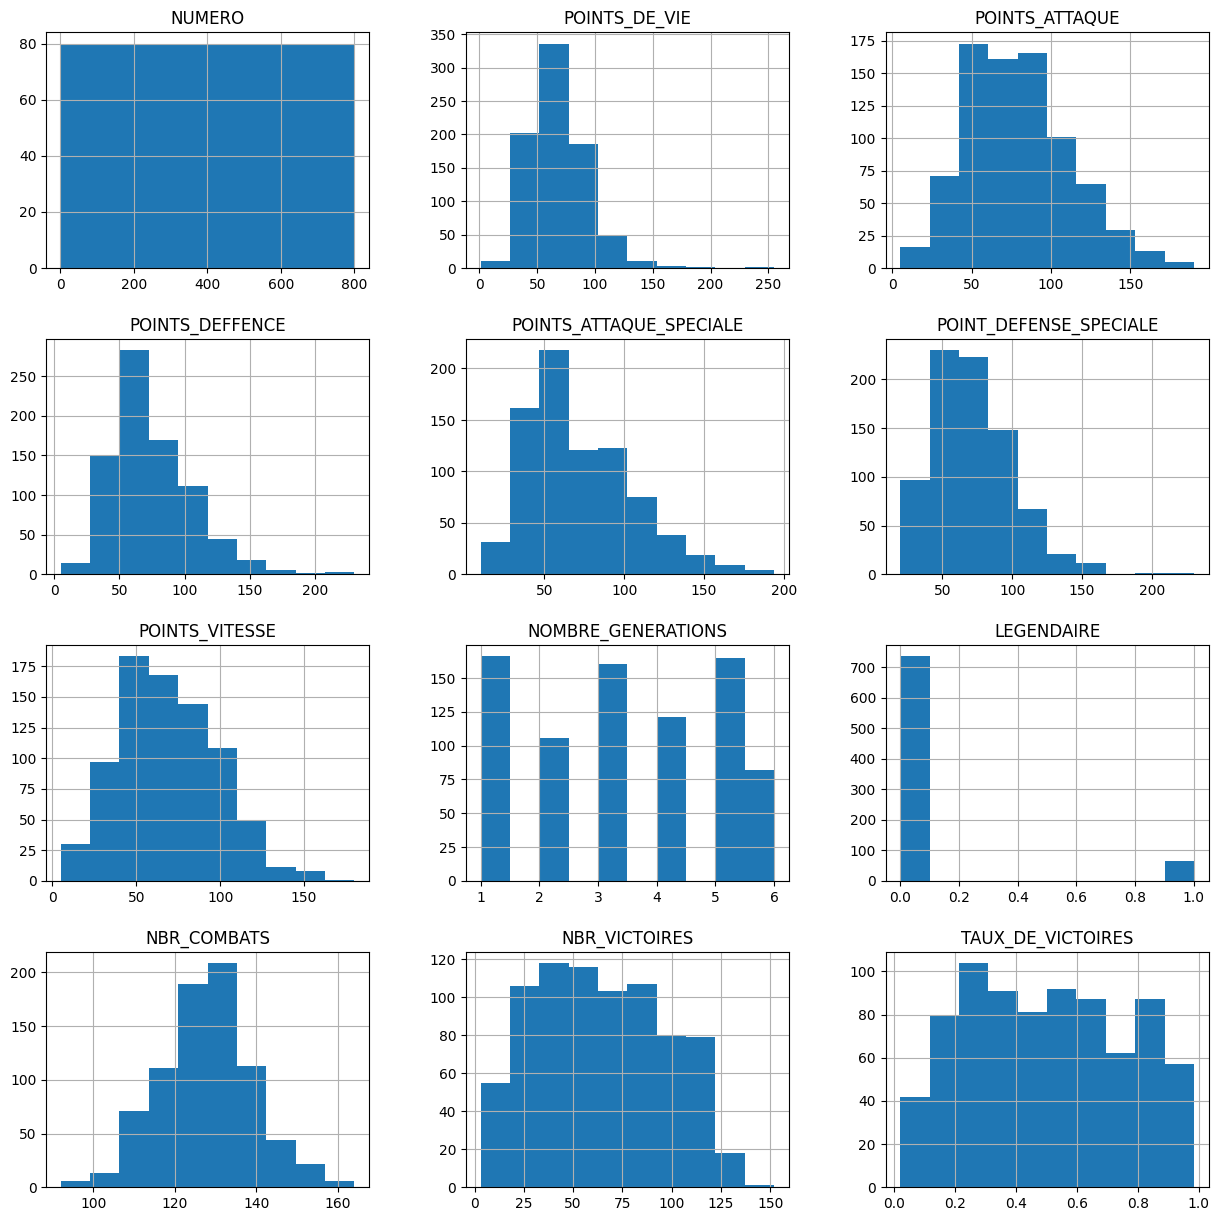

In [83]:
hist_nouveauPokedex = nouveauPokedex.hist(figsize = (15,15))
print(type(hist_nouveauPokedex))

12. Ci-dessous un exemple de code (ne faites pas attention au warning!) qui génére 1 graphique permettant de visualiser le nombre de Pokémons en fonction du Type1 et selon si le Pokémen est légendaire ou pas. De la même manière, créez un graphique équivalent qui permet de visualiser le nombre de Pokémons en fonction du Type2 et selon si le Pokémen est légendaire ou pas.

/opt/jupyterlab-2022/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/jupyterlab-2022/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/jupyterlab-2022/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/jupyterlab-2022/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst

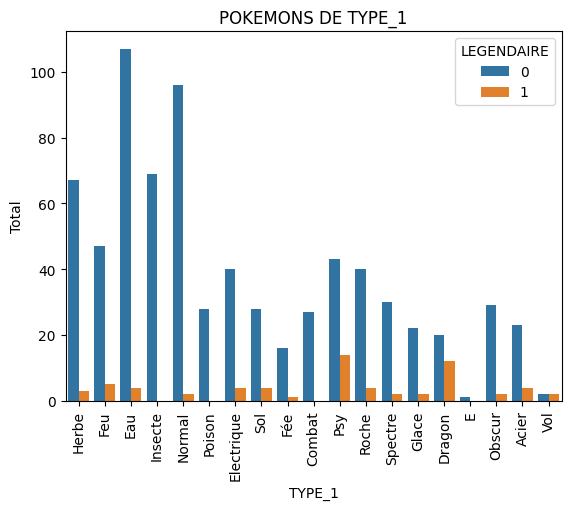

In [84]:
import matplotlib.pyplot as plt
import seaborn as sns
#Visualisation des Pokemons de type 1
axe_X = sns.countplot(x="TYPE_1", hue="LEGENDAIRE", data=nouveauPokedex)
plt.xticks(rotation= 90)
plt.xlabel('TYPE_1')
plt.ylabel('Total')
plt.title("POKEMONS DE TYPE_1")
plt.show()

**<span style="color:red">
RÉPONSE\
</span>**

/opt/jupyterlab-2022/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/jupyterlab-2022/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/jupyterlab-2022/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/opt/jupyterlab-2022/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst

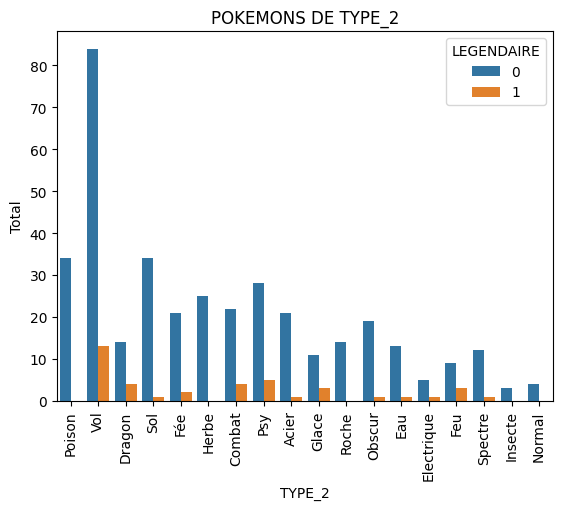

In [85]:
#Visualisation des Pokemons de type 2
axe_X = sns.countplot(x="TYPE_2", hue="LEGENDAIRE", data=nouveauPokedex)
plt.xticks(rotation= 90)
plt.xlabel('TYPE_2')
plt.ylabel('Total')
plt.title("POKEMONS DE TYPE_2")
plt.show()

13. Afin de constater d’éventuelles corrélations entre les caractéristiques numériques, créez une nouvelle DataFrame _nouveauPokedexCorr_ à partir de _nouveauPokedex_ qui ne contient que les colonnes numériques. Cette nouvelle DataFrame contient toutes les colonnes de la DataFrame  _nouveauPokedex_ hors les colonnes 'NOM', 'TYPE_1' et 'TYPE_2'


**<span style="color:red">
RÉPONSE\
</span>**

In [49]:
nouveauPokedexCorr = nouveauPokedex[['POINTS_DE_VIE','POINTS_ATTAQUE', 'POINTS_DEFFENCE', 'POINTS_ATTAQUE_SPECIALE', 'POINT_DEFENSE_SPECIALE', 
                                    'POINTS_VITESSE', 'NOMBRE_GENERATIONS', 'LEGENDAIRE', 'NBR_COMBATS', 'NBR_VICTOIRES', 'TAUX_DE_VICTOIRES']]

NameError: name 'nouveauPokedex' is not defined

14. Affichez le graphique des correlations avec la _HeatMap_ de la biblio _seaborn_

**<span style="color:red">
RÉPONSE\
</span>**

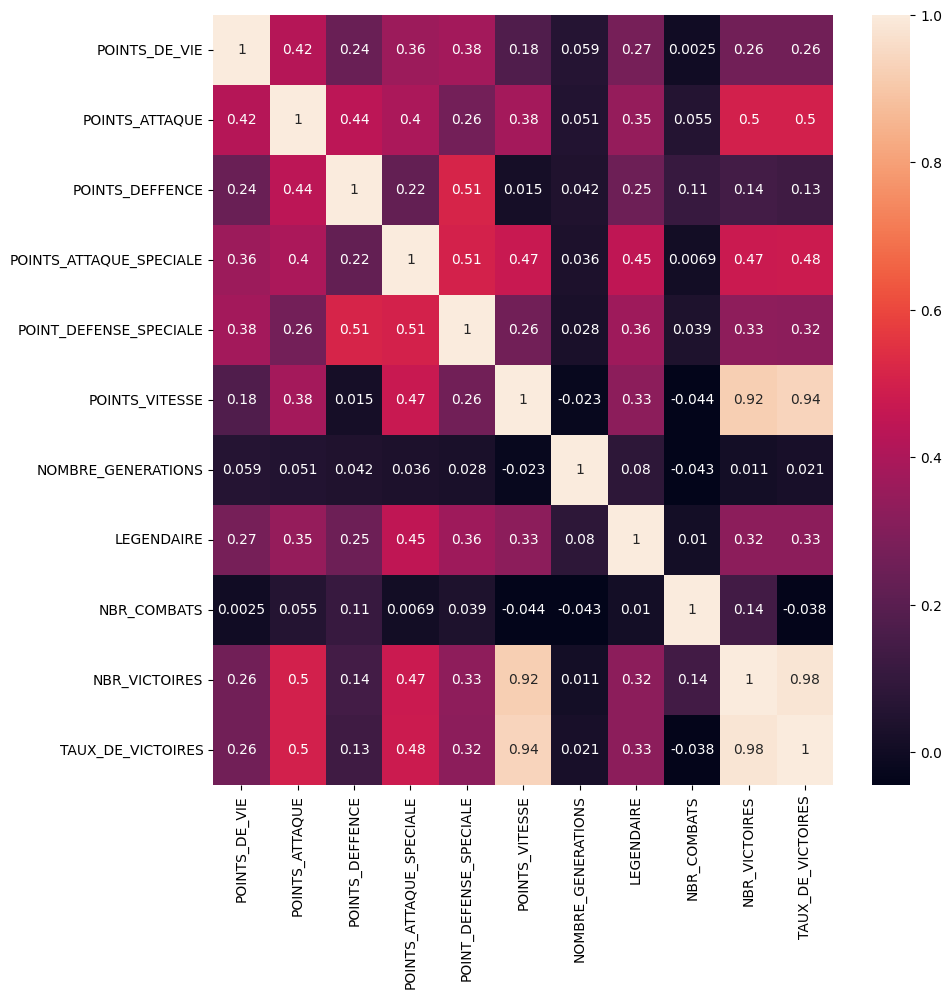

In [91]:
plt.subplots(figsize=(10,10))
corr = nouveauPokedexCorr.corr() 
sns.heatmap(corr,annot=True) 
plt.show()